# 09 — FEATURE HSV HISTOGRAM 16×16×16 | KNN

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import product
import sys

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from IPython.display import display

PROJECT_ROOT = Path(r"C:\CS231")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.value_metrics import evaluate_classification

DATA_ROOT = PROJECT_ROOT / "DATA"

## 1. Đọc dữ liệu

In [2]:
def load_images_from_folder(folder):
    images = []
    labels = []
    folder = Path(folder)

    class_names = sorted(
        [d.name for d in folder.iterdir() if d.is_dir() and d.name.isdigit()],
        key=int
    )

    for class_name in class_names:
        class_folder = folder / class_name
        for img_path in sorted(class_folder.glob("*.png")):
            img = cv2.imread(str(img_path))
            if img is None:
                continue

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            images.append(img)
            labels.append(int(class_name))

    return images, labels, class_names

In [3]:
train_folder = DATA_ROOT / "train"
dev_folder = DATA_ROOT / "dev"

train_images, train_labels, train_class_names = load_images_from_folder(train_folder)
dev_images, dev_labels, dev_class_names = load_images_from_folder(dev_folder)

y_train = np.asarray(train_labels, dtype=np.int64)
y_dev = np.asarray(dev_labels, dtype=np.int64)

print(f"Số ảnh train: {len(train_images)} | Số nhãn: {len(y_train)}")
print(f"Số ảnh dev:   {len(dev_images)} | Số nhãn: {len(y_dev)}")
print("Các lớp (VND):", train_class_names)
print("Shape ảnh mẫu:", train_images[0].shape)

Số ảnh train: 12494 | Số nhãn: 12494
Số ảnh dev:   1564 | Số nhãn: 1564
Các lớp (VND): ['10000', '20000', '50000', '100000', '200000', '500000']
Shape ảnh mẫu: (640, 640, 3)


## 2. Trích xuất Histogram HSV theo lab


In [4]:
HSV_BINS = 16 

def extract_hsv_histogram(image, bins=16):

    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist(
        [hsv_image], [0, 1, 2], None,
        [bins, bins, bins],
        [0, 180, 0, 256, 0, 256]
    )
    hist = cv2.normalize(hist, hist).flatten()
    return np.array(hist)

In [5]:
sample_rgb = train_images[0]
sample_hsv_feature = extract_hsv_histogram(sample_rgb, bins=HSV_BINS)

print("Ảnh RGB mẫu:", sample_rgb.shape)
print("HSV feature shape:", sample_hsv_feature.shape)
print("HSV feature dtype:", sample_hsv_feature.dtype)
print("HSV feature L2 norm:", np.linalg.norm(sample_hsv_feature))
print("Min/Max:", sample_hsv_feature.min(), sample_hsv_feature.max())


Ảnh RGB mẫu: (640, 640, 3)
HSV feature shape: (4096,)
HSV feature dtype: float32
HSV feature L2 norm: 1.0
Min/Max: 0.0 0.44607404


## 3. Trực quan hóa Histogram HSV

Vì HSV trong lab là **histogram 3 chiều kết hợp**, ta không thể cắt vector thành ba đoạn 256 chiều như với RGB. Thay vào đó, reshape vector thành khối `(16, 16, 16)`, rồi cộng các trục còn lại để quan sát phân bố **theo H**, **theo S**, **theo V**.

- **H (Hue):** sắc độ, giá trị OpenCV `0–179`.
- **S (Saturation):** độ bão hòa, `0–255`.
- **V (Value):** độ sáng, `0–255`.

Các cột dưới đây là **tổng các bin của histogram 3D đã chuẩn hóa L2**, **không** phải phần trăm pixel và **không** phải ba histogram được chuẩn hóa riêng.

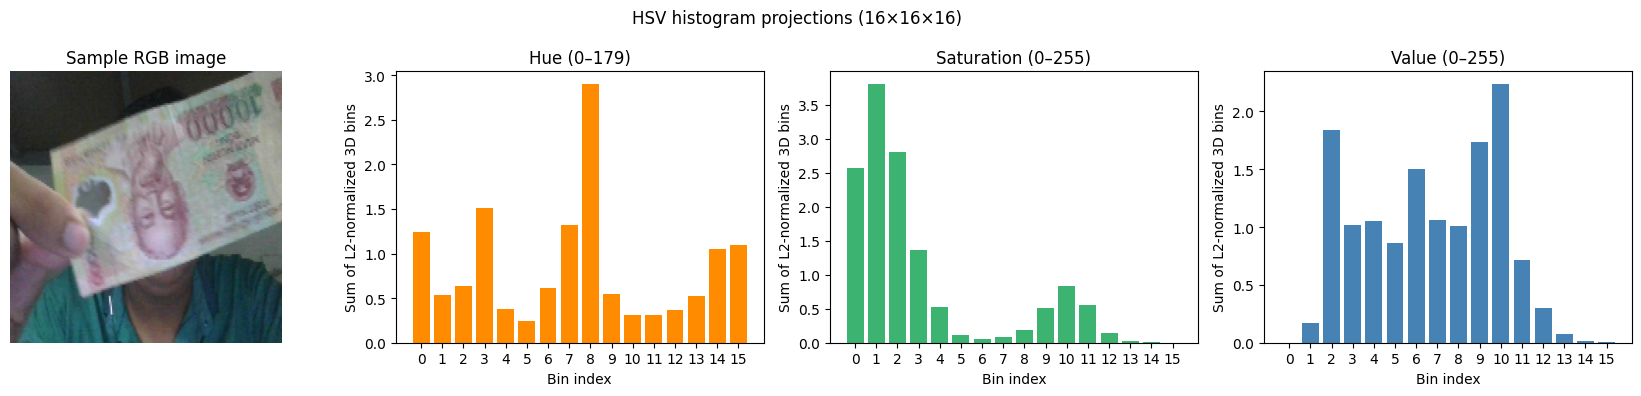

In [6]:
# Hình ảnh gốc và ba hình chiếu 1D của histogram HSV 3D
hsv_cube = sample_hsv_feature.reshape(HSV_BINS, HSV_BINS, HSV_BINS)
h_projection = hsv_cube.sum(axis=(1, 2))
s_projection = hsv_cube.sum(axis=(0, 2))
v_projection = hsv_cube.sum(axis=(0, 1))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].imshow(sample_rgb)
axes[0].set_title("Sample RGB image")
axes[0].axis("off")

for ax, values, title, color in zip(
    axes[1:],
    [h_projection, s_projection, v_projection],
    ["Hue (0–179)", "Saturation (0–255)", "Value (0–255)"],
    ["darkorange", "mediumseagreen", "steelblue"]
):
    ax.bar(range(HSV_BINS), values, color=color)
    ax.set_title(title)
    ax.set_xlabel("Bin index")
    ax.set_xticks(range(HSV_BINS))
    ax.set_ylabel("Sum of L2-normalized 3D bins")

plt.suptitle(f"HSV histogram projections ({HSV_BINS}×{HSV_BINS}×{HSV_BINS})")
plt.tight_layout()
plt.show()

In [7]:
TOP_N = 10
top_indices = np.argsort(sample_hsv_feature)[::-1][:TOP_N]

top_bins = [
    (*np.unravel_index(int(idx), (HSV_BINS, HSV_BINS, HSV_BINS)),
     float(sample_hsv_feature[idx]))
    for idx in top_indices
]

display(pd.DataFrame(top_bins, columns=["H_bin", "S_bin", "V_bin", "L2_value"]))

,H_bin,S_bin,V_bin,L2_value
0,3,2,2,0.446074
1,2,0,2,0.226751
2,8,10,6,0.204732
3,8,10,4,0.197006
4,7,1,10,0.177342
5,3,1,10,0.172534
6,8,11,4,0.168422
7,3,1,2,0.152604
8,7,1,6,0.136853
9,3,0,10,0.136521


**Gợi ý nhận xét sau khi chạy:** xác định bin H/S/V có tổng giá trị lớn, những tổ hợp `(H_bin, S_bin, V_bin)` nổi bật, và ghi rõ rằng histogram không giữ vị trí không gian của màu trên tờ tiền. Chưa thể kết luận HSV tốt hơn RGB chỉ từ biểu đồ một ảnh; cần so sánh trên dev.

## 4. Trích xuất ma trận feature cho train / dev

In [8]:
X_train_hsv = np.asarray(
    [extract_hsv_histogram(img, bins=HSV_BINS) for img in train_images],
    dtype=np.float32
)
X_dev_hsv = np.asarray(
    [extract_hsv_histogram(img, bins=HSV_BINS) for img in dev_images],
    dtype=np.float32
)

print("Train:", X_train_hsv.shape, y_train.shape)
print("Dev:  ", X_dev_hsv.shape, y_dev.shape)

Train: (12494, 4096) (12494,)
Dev:   (1564, 4096) (1564,)


## 5. Huấn luyện KNN — Grid Search riêng cho HSV


In [9]:
n_neighbors_options = range(1, 11)
weight_options = ["uniform", "distance"]
metric_options = [
    "braycurtis",
    "canberra",
    "correlation",
    "cosine",
    "euclidean",
    "minkowski",
]

results_hsv = []

for order, (k, weight, metric) in enumerate(
    product(n_neighbors_options, weight_options, metric_options)
):
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights=weight,
        metric=metric,
        algorithm="brute"
    )
    knn.fit(X_train_hsv, y_train)
    y_pred = knn.predict(X_dev_hsv)
    scores = evaluate_classification(y_dev, y_pred)

    results_hsv.append({
        "k": k,
        "weights": weight,
        "metric": metric,
        "macro_f1": scores["macro_f1"],
        "mae_vnd": scores["mae_vnd"],
        "accuracy": scores["accuracy"],
        "_order": order,
    })

df_results_hsv = (
    pd.DataFrame(results_hsv)
    .sort_values(
        ["macro_f1", "mae_vnd", "_order"],
        ascending=[False, True, True]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("Tổng số cấu hình:", len(df_results_hsv))
display(df_results_hsv.head(10))

Tổng số cấu hình: 120


,k,weights,metric,macro_f1,mae_vnd,accuracy
0,3,distance,braycurtis,0.897362,23305.626598,0.892583
1,4,distance,braycurtis,0.896408,23861.892583,0.892583
2,1,uniform,braycurtis,0.896137,24884.910486,0.892583
3,1,distance,braycurtis,0.896137,24884.910486,0.892583
4,2,distance,braycurtis,0.896137,24884.910486,0.892583
5,5,distance,braycurtis,0.890636,24526.854220,0.886829
6,6,distance,braycurtis,0.888851,24565.217391,0.885550
7,7,distance,braycurtis,0.885132,26323.529412,0.881074
8,3,uniform,braycurtis,0.885030,26157.289003,0.879795
9,8,distance,braycurtis,0.885007,27263.427110,0.881714


In [10]:
# Chọn cấu hình tốt nhất và so sánh các khoảng cách
best_hsv = df_results_hsv.iloc[0]
print("Cấu hình HSV tốt nhất trên DEV:")
print(best_hsv.to_string())

best_by_metric_hsv = (
    df_results_hsv
    .drop_duplicates(subset="metric", keep="first")
    .sort_values("macro_f1", ascending=False, kind="stable")
)

display(best_by_metric_hsv[
    ["metric", "k", "weights", "macro_f1", "mae_vnd", "accuracy"]
])

Cấu hình HSV tốt nhất trên DEV:
k                      3
weights         distance
metric        braycurtis
macro_f1        0.897362
mae_vnd     23305.626598
accuracy        0.892583


,metric,k,weights,macro_f1,mae_vnd,accuracy
0,braycurtis,3,distance,0.897362,23305.626598,0.892583
20,canberra,4,distance,0.849348,32576.726343,0.845908
40,cosine,6,distance,0.767521,53842.710997,0.764066
43,euclidean,6,distance,0.762364,54942.455243,0.758312
44,minkowski,6,distance,0.762364,54942.455243,0.758312
45,correlation,5,distance,0.761000,53574.168798,0.757033


## 6. Confusion matrix của cấu hình HSV tốt nhất trên dev

In [11]:
# Đọc trực tiếp tham số từ Grid Search (không hard-code như ví dụ RGB cũ)
best_knn_hsv = KNeighborsClassifier(
    n_neighbors=int(best_hsv["k"]),
    weights=str(best_hsv["weights"]),
    metric=str(best_hsv["metric"]),
    algorithm="brute"
)
best_knn_hsv.fit(X_train_hsv, y_train)
y_dev_pred_hsv = best_knn_hsv.predict(X_dev_hsv)

hsv_scores = evaluate_classification(y_dev, y_dev_pred_hsv)
print("DEV Accuracy:", hsv_scores["accuracy"])
print("DEV Macro-F1:", hsv_scores["macro_f1"])
print("DEV MAE_VND:", hsv_scores["mae_vnd"])


DEV Accuracy: 0.8925831202046036
DEV Macro-F1: 0.8973616984582596
DEV MAE_VND: 23305.626598465475


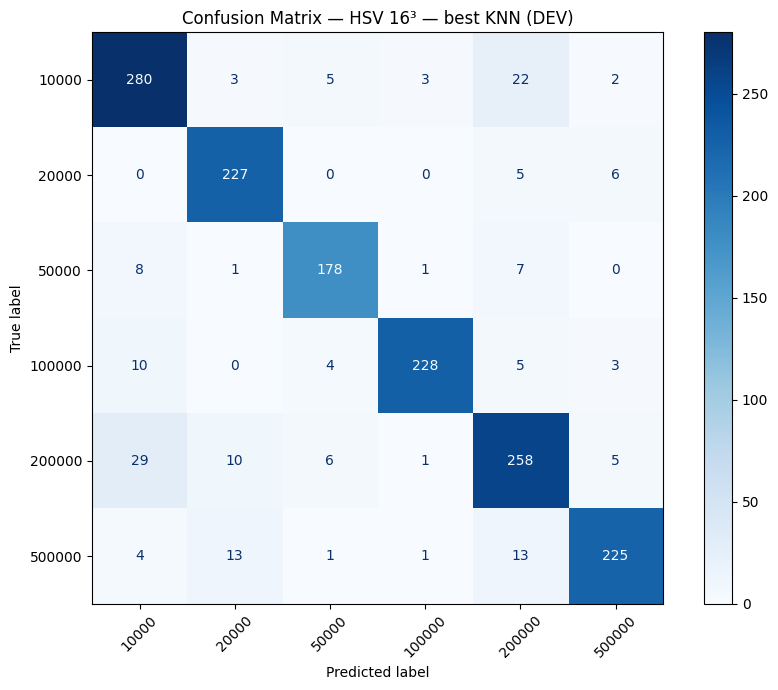

In [12]:
labels = np.sort(np.unique(y_train))
cm_hsv = confusion_matrix(y_dev, y_dev_pred_hsv, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hsv,
    display_labels=labels
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
ax.set_title(f"Confusion Matrix — HSV {HSV_BINS}³ — best KNN (DEV)")
plt.tight_layout()
plt.show()

In [13]:
# Precision / Recall / F1 theo mệnh giá — đọc được lớp nào mạnh/yếu
report_hsv = classification_report(
    y_dev, y_dev_pred_hsv,
    labels=labels,
    output_dict=True,
    zero_division=0
)

per_class_hsv = pd.DataFrame([
    {
        "denomination_vnd": int(label),
        "precision": report_hsv[str(label)]["precision"],
        "recall": report_hsv[str(label)]["recall"],
        "f1": report_hsv[str(label)]["f1-score"],
        "support": int(report_hsv[str(label)]["support"]),
    }
    for label in labels
])
display(per_class_hsv)

print(f"Số ảnh đúng: {np.trace(cm_hsv)}/{cm_hsv.sum()}")

,denomination_vnd,precision,recall,f1,support
0,10000,0.845921,0.888889,0.866873,315
1,20000,0.893701,0.953782,0.922764,238
2,50000,0.917526,0.912821,0.915167,195
3,100000,0.974359,0.912000,0.942149,250
4,200000,0.832258,0.834951,0.833603,309
5,500000,0.933610,0.875486,0.903614,257


Số ảnh đúng: 1396/1564


In [14]:
# Những cặp mệnh giá có tổng số nhầm lẫn hai chiều lớn nhất
error_pairs_hsv = []
for i in range(len(labels)):
    for j in range(i + 1, len(labels)):
        errors_ij = int(cm_hsv[i, j])
        errors_ji = int(cm_hsv[j, i])
        error_pairs_hsv.append({
            "pair": f"{labels[i]} ↔ {labels[j]}",
            "true_i_pred_j": errors_ij,
            "true_j_pred_i": errors_ji,
            "total_errors": errors_ij + errors_ji,
        })

df_error_pairs_hsv = (
    pd.DataFrame(error_pairs_hsv)
    .sort_values("total_errors", ascending=False, kind="stable")
)
print("Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:")
display(df_error_pairs_hsv.head(5))

Top 5 cặp mệnh giá nhầm lẫn nhiều nhất:


,pair,true_i_pred_j,true_j_pred_i,total_errors
3,10000 ↔ 200000,22,29,51
8,20000 ↔ 500000,6,13,19
14,200000 ↔ 500000,5,13,18
7,20000 ↔ 200000,5,10,15
1,10000 ↔ 50000,5,8,13


## Lưu kết quả cho bước so sánh bốn feature

In [15]:
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

summary_hsv = pd.DataFrame([{
    "feature": f"Histogram HSV {HSV_BINS}x{HSV_BINS}x{HSV_BINS}",
    "feature_dim": HSV_BINS ** 3,
    "k": int(best_hsv["k"]),
    "weights": str(best_hsv["weights"]),
    "metric": str(best_hsv["metric"]),
    "macro_f1": float(best_hsv["macro_f1"]),
    "mae_vnd": float(best_hsv["mae_vnd"]),
    "accuracy": float(best_hsv["accuracy"]),
}])

df_results_hsv.to_csv(output_dir / "hsv16_knn_grid_dev.csv", index=False)
summary_hsv.to_csv(output_dir / "hsv16_best_dev.csv", index=False)
pd.DataFrame(cm_hsv, index=labels, columns=labels).to_csv(
    output_dir / "hsv16_confusion_matrix_dev.csv"
)
per_class_hsv.to_csv(output_dir / "hsv16_per_class_dev.csv", index=False)

print("Đã lưu vào:", output_dir.resolve())
display(summary_hsv)

Đã lưu vào: C:\CS231\src\KNN\results


,feature,feature_dim,k,weights,metric,macro_f1,mae_vnd,accuracy
0,Histogram HSV 16x16x16,4096,3,distance,braycurtis,0.897362,23305.626598,0.892583
